In [27]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = Path("../data/raw/Telco-Customer-Churn.csv")
df = pd.read_csv(DATA_PATH)
print(f"Dataset shape: {df.shape}")

Dataset shape: (7043, 21)


In [28]:
display(df.head())
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types:")
print(df.dtypes)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Dataset shape: (7043, 21)

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object


In [29]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nUnique values per column:")
print(df.nunique())





Missing values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicate rows: 0

Unique values per column:
customerID          7043
gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
tenure                73
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies        3
Contract               3
PaperlessBilling       2
PaymentMethod          4
MonthlyCharge

Churn counts
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn percentages:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


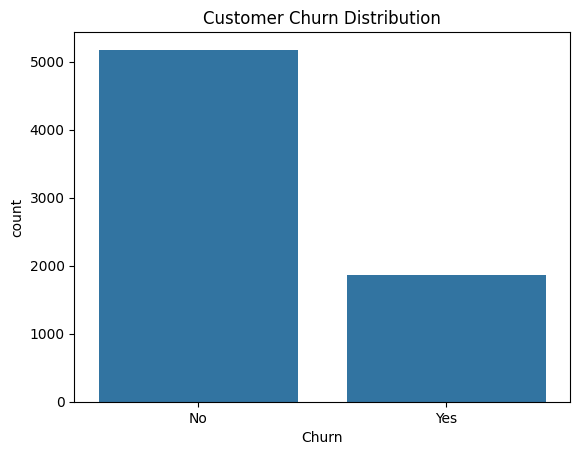

In [30]:
churn_counts =df["Churn"].value_counts()
print("Churn counts")
print(churn_counts)

print("\nChurn percentages:")
print((df["Churn"].value_counts(normalize=True) * 100).round(2))

sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.show()

            tenure  MonthlyCharges
count  7043.000000     7043.000000
mean     32.371149       64.761692
std      24.559481       30.090047
min       0.000000       18.250000
25%       9.000000       35.500000
50%      29.000000       70.350000
75%      55.000000       89.850000
max      72.000000      118.750000


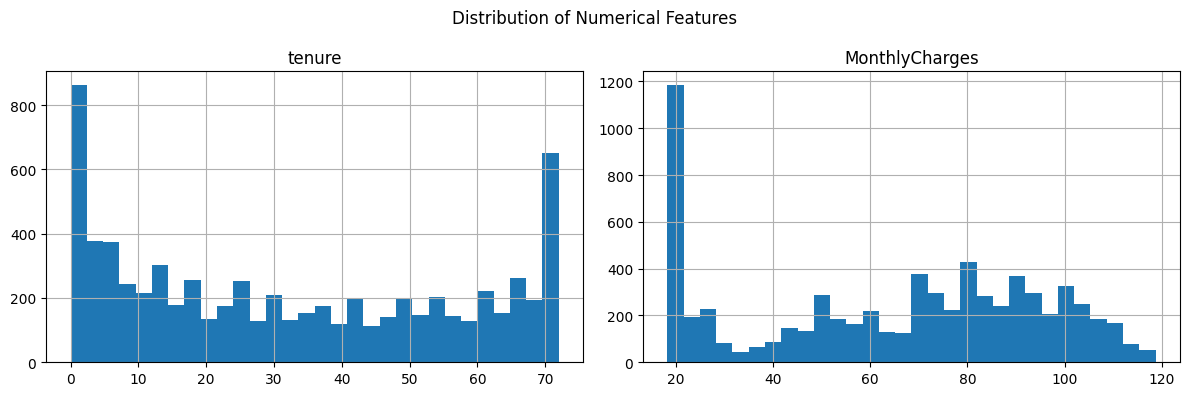

In [31]:
numerical_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

print(df[numerical_cols].describe())

df[numerical_cols].hist(bins=30, figsize=(12, 4))
plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


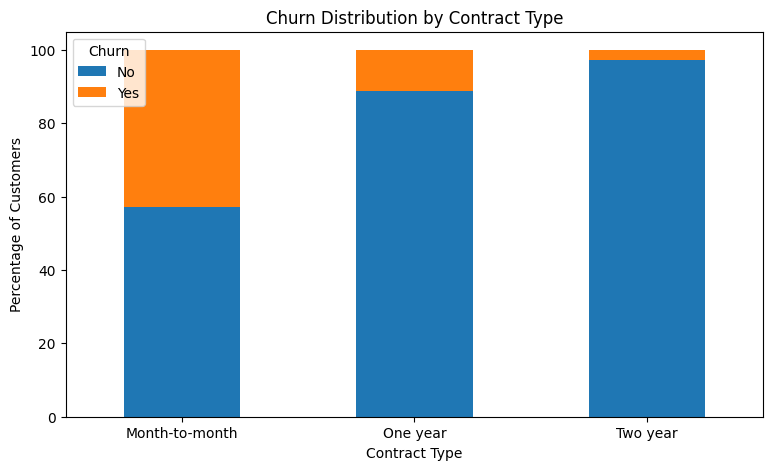

In [32]:
contract_churn = pd.crosstab(df["Contract"], df["Churn"], normalize="index") * 100

print(contract_churn.round(2))

contract_churn.plot(kind="bar", stacked=True, figsize=(9, 5))
plt.title("Churn Distribution by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation=0)
plt.show()

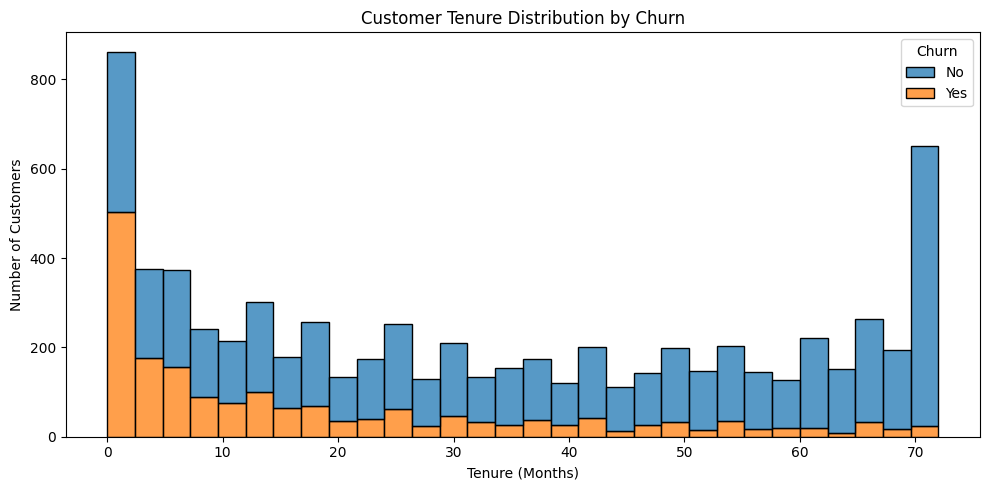

In [33]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x="tenure", hue="Churn", bins=30, multiple="stack")
plt.title("Customer Tenure Distribution by Churn")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

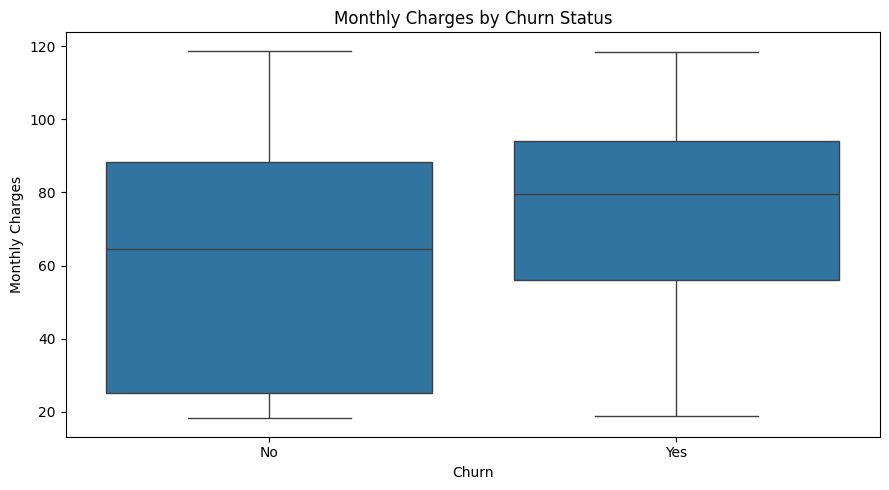

In [34]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.show()


Churn                         No    Yes
PaymentMethod                          
Bank transfer (automatic)  83.29  16.71
Credit card (automatic)    84.76  15.24
Electronic check           54.71  45.29
Mailed check               80.89  19.11


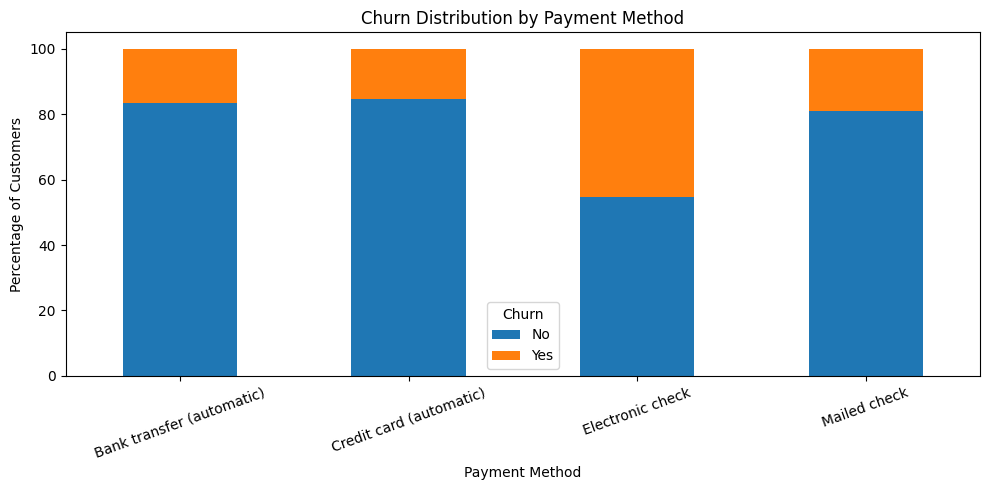

In [35]:
payment_churn = pd.crosstab(df["PaymentMethod"], df["Churn"], normalize="index") * 100

print(payment_churn.round(2))

payment_churn.plot(kind="bar", stacked=True, figsize=(10, 5))
plt.title("Churn Distribution by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

Churn               No    Yes
InternetService              
DSL              81.04  18.96
Fiber optic      58.11  41.89
No               92.60   7.40


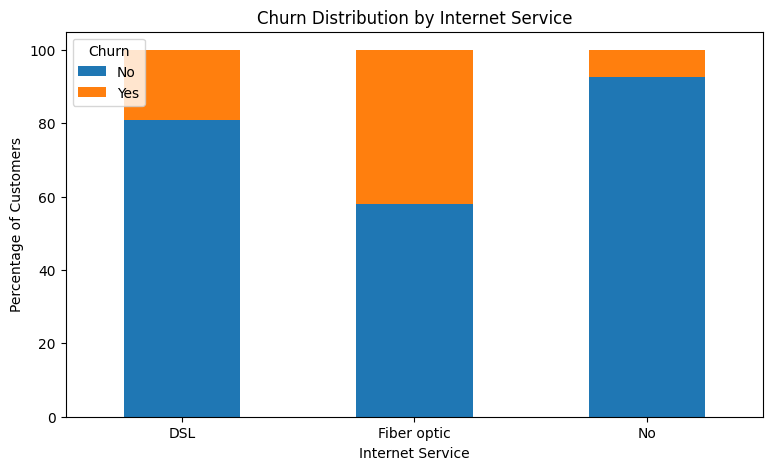

In [36]:
internet_churn = pd.crosstab(df["InternetService"], df["Churn"], normalize="index") * 100

print(internet_churn.round(2))

internet_churn.plot(kind="bar", stacked=True, figsize=(9, 5))
plt.title("Churn Distribution by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation=0)
plt.show()

Churn             No    Yes
SeniorCitizen              
0              76.39  23.61
1              58.32  41.68


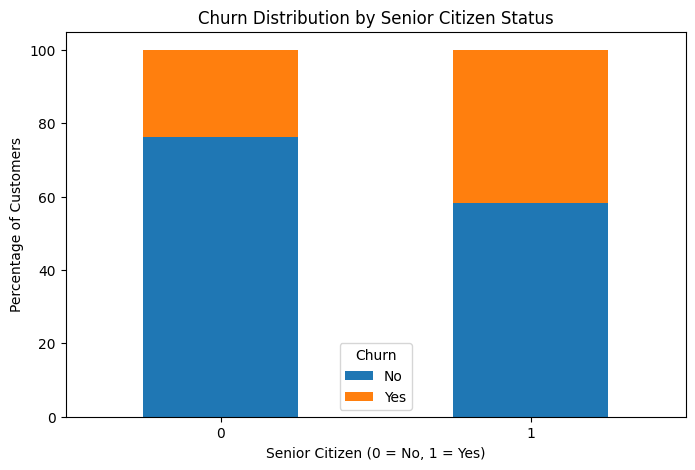

In [37]:
senior_churn = pd.crosstab(df["SeniorCitizen"], df["Churn"], normalize="index") * 100

print(senior_churn.round(2))

senior_churn.plot(kind="bar", stacked=True, figsize=(8, 5))
plt.title("Churn Distribution by Senior Citizen Status")
plt.xlabel("Senior Citizen (0 = No, 1 = Yes)")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation=0)
plt.show()

Churn           No    Yes
TenureGroup              
0-12         52.56  47.44
13-24        71.29  28.71
25-48        79.61  20.39
49-72        90.49   9.51


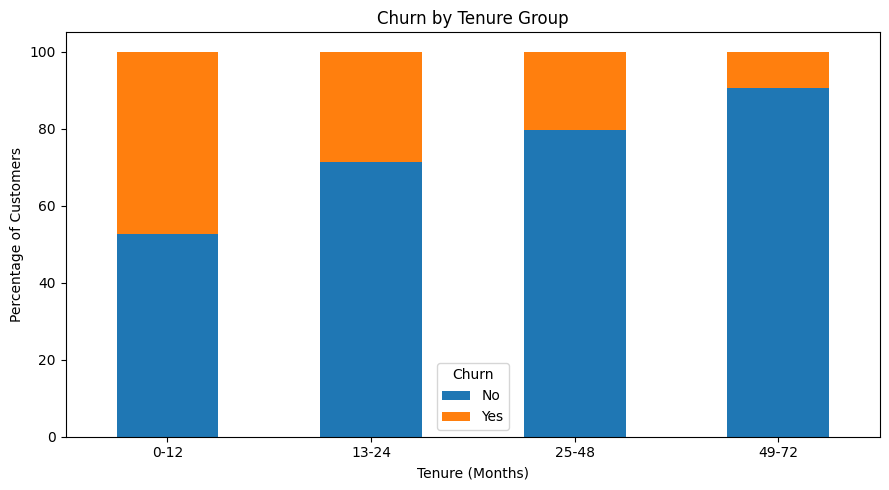

In [38]:
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[0, 12, 24, 48, 72],
    labels=["0-12", "13-24", "25-48", "49-72"],
    include_lowest=True
)
tenure_churn = pd.crosstab(df["TenureGroup"], df["Churn"], normalize="index") * 100
print(tenure_churn.round(2))
tenure_churn.plot(kind="bar", stacked=True, figsize=(9, 5))
plt.title("Churn by Tenure Group")
plt.xlabel("Tenure (Months)")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

                tenure  MonthlyCharges  TotalCharges
tenure            1.00            0.25          0.83
MonthlyCharges    0.25            1.00          0.65
TotalCharges      0.83            0.65          1.00


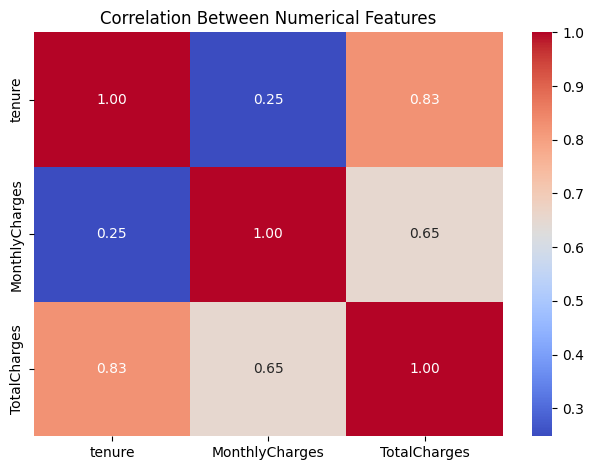

In [39]:
numerical_df = df[["tenure", "MonthlyCharges", "TotalCharges"]].copy()
numerical_df["TotalCharges"] = pd.to_numeric(numerical_df["TotalCharges"], errors="coerce")
correlation = numerical_df.corr()

print(correlation.round(2))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()


Churn by Partner:
Churn       No    Yes
Partner              
No       67.04  32.96
Yes      80.34  19.66


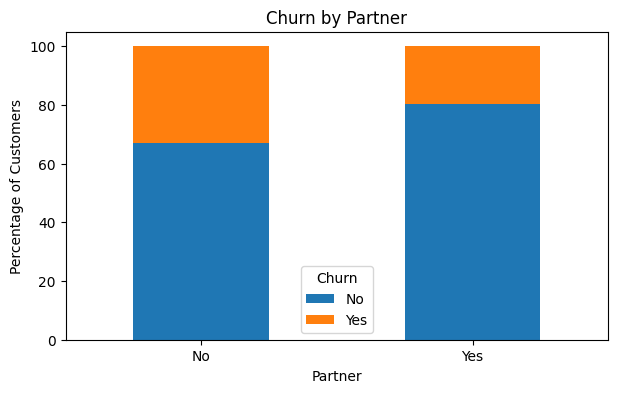


Churn by Dependents:
Churn          No    Yes
Dependents              
No          68.72  31.28
Yes         84.55  15.45


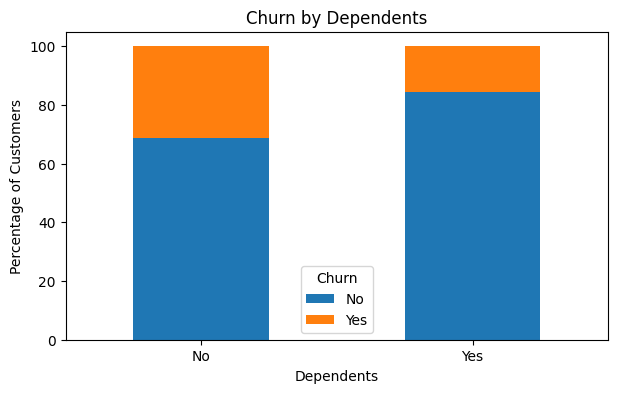

In [40]:
for col in ["Partner", "Dependents"]:
    rates = pd.crosstab(df[col], df["Churn"], normalize="index") * 100
    print(f"\nChurn by {col}:")
    print(rates.round(2))
    rates.plot(kind="bar", stacked=True, figsize=(7, 4))
    plt.title(f"Churn by {col}")
    plt.ylabel("Percentage of Customers")
    plt.xticks(rotation=0)
    plt.show()

In [41]:
print("Data types:")
print(df.dtypes)

print("\nBlank TotalCharges:", df["TotalCharges"].astype(str).str.strip().eq("").sum())
print("Non-numeric TotalCharges:", pd.to_numeric(df["TotalCharges"], errors="coerce").isna().sum())
print("\nSample TotalCharges:", df["TotalCharges"].head(10).tolist())

Data types:
customerID            object
gender                object
SeniorCitizen          int64
Partner               object
Dependents            object
tenure                 int64
PhoneService          object
MultipleLines         object
InternetService       object
OnlineSecurity        object
OnlineBackup          object
DeviceProtection      object
TechSupport           object
StreamingTV           object
StreamingMovies       object
Contract              object
PaperlessBilling      object
PaymentMethod         object
MonthlyCharges       float64
TotalCharges          object
Churn                 object
TenureGroup         category
dtype: object

Blank TotalCharges: 11
Non-numeric TotalCharges: 11

Sample TotalCharges: ['29.85', '1889.5', '108.15', '1840.75', '151.65', '820.5', '1949.4', '301.9', '3046.05', '3487.95']


In [42]:
for col in ["Contract", "InternetService", "PaymentMethod", "TechSupport"]:
    rates = pd.crosstab(df[col], df["Churn"], normalize="index") * 100
    print(f"\n{col} — churn rate:")
    print(rates["Yes"].round(2).astype(str) + "%")



Contract — churn rate:
Contract
Month-to-month    42.71%
One year          11.27%
Two year           2.83%
Name: Yes, dtype: object

InternetService — churn rate:
InternetService
DSL            18.96%
Fiber optic    41.89%
No               7.4%
Name: Yes, dtype: object

PaymentMethod — churn rate:
PaymentMethod
Bank transfer (automatic)    16.71%
Credit card (automatic)      15.24%
Electronic check             45.29%
Mailed check                 19.11%
Name: Yes, dtype: object

TechSupport — churn rate:
TechSupport
No                     41.64%
No internet service      7.4%
Yes                    15.17%
Name: Yes, dtype: object
